In [69]:
import pandas as pd
import folium as fl
import geopandas as geo
import altair as alt

# Projeto de Análise Exploratória de Dados

##### Autores: Miguel Vitor Pereira; Ricardo Rodrigues Tose; Daniel Furtado Nunes Rocha da Silva
##### Professor: João Lucas Rulff da Costa

## Introdução

Esse trabalho tem como objetivo investigar a relação entre a gravidade dos acidentes com o horário, tipo de acidente, condições da via e do tempo. Buscaremos identificar padrões que orientem as discussões.

Não é necessário nenhum conhecimento prévio sobre o tema. 

## Dados e método

Utilizaremos a base pública da Polícia Rodoviária Federal (PRF), obtida por download do arquivo datatran2025.csv, na versão agrupada por ocorrência. A base nacional consultada contém 72.529 registros e 30 colunas; selecionaremos Minas Gerais, Espírito Santo, Rio de Janeiro e São Paulo no ano de 2025. Para esta análise, consideraremos grave a ocorrência com ao menos um morto ou ferido grave. Verificaremos duplicidades, valores ausentes e categorias antes de calcular contagens e proporções. Sem dados de fluxo de veículos, os resultados descreverão os acidentes registrados, sem estimar o risco por viagem ou estabelecer causalidade.

Observação: Ao pesquisar, foi descoberto que a PRF usa como georreferenciamento o SIRGAS 2000. 

# Preparação do dataset

In [70]:
df = pd.read_csv(r"datatran2025.csv",encoding="latin1",sep=";",decimal=",")
sudeste = df[df["uf"].isin(["SP", "MG", "ES", "RJ"])].copy()
sudeste.isna().sum()
#Existem alguns valores nulos, iremos verificar o que são.

id                         0
data_inversa               0
dia_semana                 0
horario                    0
uf                         0
br                         0
km                         0
municipio                  0
causa_acidente             0
tipo_acidente              0
classificacao_acidente     0
fase_dia                   0
sentido_via                0
condicao_metereologica     0
tipo_pista                 0
tracado_via                0
uso_solo                   0
pessoas                    0
mortos                     0
feridos_leves              0
feridos_graves             0
ilesos                     0
ignorados                  0
feridos                    0
veiculos                   0
latitude                   0
longitude                  0
regional                   0
delegacia                 10
uop                       16
dtype: int64

In [71]:
sudeste[sudeste.isna().any(axis=1)]

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
22094,657145,2025-01-24,sexta-feira,22:05:00,RJ,0,0.0,NITEROI,Frear bruscamente,Colisão traseira,...,0,7,0,0,5,-22.859970,-43.102393,SPRF-RJ,NaN,NaN
28458,666766,2025-02-21,sexta-feira,21:15:00,RJ,0,0.0,RIO DE JANEIRO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,7,0,0,2,-22.806135,-43.355273,SPRF-RJ,NaN,NaN
30176,669357,2025-03-24,segunda-feira,18:30:00,RJ,0,0.0,RIO DE JANEIRO,Acumulo de areia ou detritos sobre o pavimento,Colisão frontal,...,0,3,0,0,1,-22.808860,-43.341883,SPRF-RJ,NaN,NaN
31329,671127,2025-02-06,quinta-feira,23:00:00,RJ,0,0.0,SAO GONCALO,Pista Escorregadia,Colisão com objeto,...,0,3,0,0,1,-22.787730,-43.007542,SPRF-RJ,NaN,NaN
35906,689128,2025-04-28,segunda-feira,18:05:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Colisão transversal,...,0,2,1,0,3,-22.962698,-43.203970,SPRF-RJ,DEL08-RJ,NaN
36475,690004,2025-05-09,sexta-feira,11:25:00,ES,0,0.0,VITORIA,Reação tardia ou ineficiente do condutor,Colisão transversal,...,0,2,0,0,2,-20.309857,-40.314471,SPRF-ES,NaN,NaN
44428,701773,2025-07-01,terça-feira,08:20:00,RJ,0,0.0,RIO DE JANEIRO,Condutor desrespeitou a iluminação vermelha do...,Colisão transversal,...,0,1,2,1,3,-22.985000,-43.191000,SPRF-RJ,DEL01-RJ,NaN
45077,702739,2025-07-05,sábado,16:00:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Colisão traseira,...,0,1,0,1,2,-22.980540,-43.365787,SPRF-RJ,NaN,NaN
45200,702907,2025-06-26,quinta-feira,13:45:00,RJ,0,0.0,RIO DE JANEIRO,Frear bruscamente,Colisão traseira,...,0,1,1,1,3,-22.904944,-43.190666,SPRF-RJ,NaN,NaN
45241,702957,2025-07-06,domingo,14:05:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Queda de ocupante de veículo,...,0,1,0,1,2,-22.983351,-43.189795,SPRF-RJ,NaN,NaN


Os dados nulos se limitam a quais delegacias e unidade operacional, como todos os outros dados estão completos e essas duas colunas não são de extrema importância, optaremos por deixá-las no dataset e se caso fizermos algum cálculo mais a frente em que esses dados sejam importantes iremos tomar outras medidas de análise.

In [72]:
sudeste["id"].nunique() == sudeste["id"].count()
# Não existe dados de acidentes repetidos.

np.True_

# Como os acidentes registrados se distribuem entre os estados e as rodovias do Sudeste?

In [73]:
mapa = fl.Map(
    location=[-21, -44],
    zoom_start=6
)

acidente = sudeste.iloc[0]

fl.Marker(
    location=[acidente["latitude"], acidente["longitude"]],
    tooltip="Passe o mouse aqui",
    popup=f'Município: {acidente["municipio"]}'
).add_to(mapa)

mapa

In [74]:
geometria = geo.points_from_xy(
    sudeste["longitude"],
    sudeste["latitude"]
)

acidentes_geo = geo.GeoDataFrame(
    sudeste.copy(),
    geometry=geometria
)
acidentes_geo[["municipio", "latitude", "longitude", "geometry"]].head(8)

,municipio,latitude,longitude,geometry
0,GUARULHOS,-23.485868,-46.540753,POINT (-46.54075 -23.48587)
4,FRANCISCO SA,-16.468013,-43.431213,POINT (-43.43121 -16.46801)
8,MURIAE,-21.163289,-42.379690,POINT (-42.37969 -21.16329)
11,RIO MANSO,-20.173275,-44.375455,POINT (-44.37545 -20.17328)
13,MURIAE,-21.163289,-42.379690,POINT (-42.37969 -21.16329)
19,CONSELHEIRO LAFAIETE,-20.602365,-43.806999,POINT (-43.807 -20.60237)
23,MARECHAL FLORIANO,-20.410664,-40.883802,POINT (-40.8838 -20.41066)
25,RIO DE JANEIRO,-22.867662,-43.195337,POINT (-43.19534 -22.86766)


<Axes: xlabel='x', ylabel='y'>

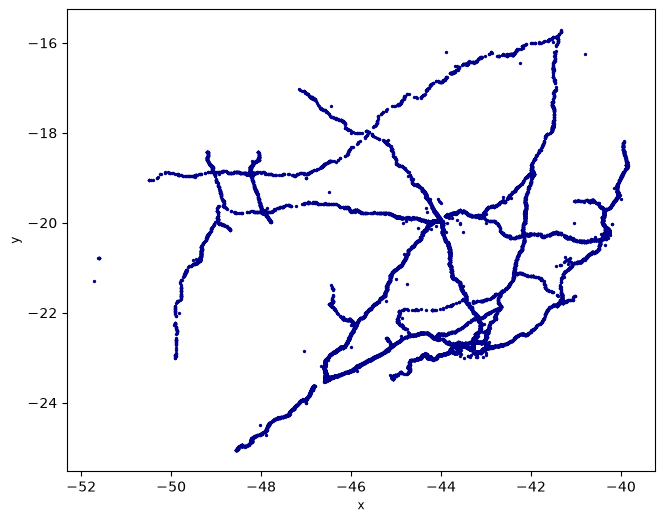

In [75]:
acidentes_geo.plot(
    figsize=(8, 6),
    markersize=2,
    color="darkblue"
)

In [81]:
dados_mapa = sudeste.sample(n=300, random_state=42).copy()

acidentes_geo = geo.GeoDataFrame(
    dados_mapa,
    geometry=geo.points_from_xy(
        dados_mapa["longitude"],
        dados_mapa["latitude"]
    ),
    crs="EPSG:4674"
)

In [82]:
fl.GeoJson(
    acidentes_geo[["municipio", "uf", "geometry"]],
    name="Acidentes",
    marker=fl.CircleMarker(
        radius=4,
        color="darkblue",
        fill=True,
        fill_opacity=0.6
    ),
    tooltip=fl.GeoJsonTooltip(
        fields=["municipio", "uf"],
        aliases=["Município:", "Estado:"]
    )
).add_to(mapa)

mapa

In [79]:
acidentes_geo

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop,geometry
672,655728,2025-01-17,sexta-feira,22:10:00,RJ,116,193.0,QUEIMADOS,Condutor deixou de manter distância do veículo...,Colisão traseira,...,1,0,1,2,-22.739602,-43.528591,SPRF-RJ,DEL06-RJ,UOP01-DEL06-RJ,POINT (-43.52859 -22.7396)
21847,656745,2025-01-22,quarta-feira,21:20:00,ES,101,147.3,LINHARES,Acessar a via sem observar a presença dos outr...,Colisão transversal,...,1,0,1,2,-19.378872,-40.066579,SPRF-ES,DEL04-ES,UOP01-DEL04-ES,POINT (-40.06658 -19.37887)
19879,653675,2025-01-07,terça-feira,10:20:00,MG,116,506.3,UBAPORANGA,Acessar a via sem observar a presença dos outr...,Colisão transversal,...,2,0,1,2,-19.611734,-42.113441,SPRF-MG,DEL06-MG,UOP02-DEL06-MG,POINT (-42.11344 -19.61173)
20962,655385,2025-01-16,quinta-feira,07:50:00,RJ,101,261.0,RIO BONITO,Ausência de reação do condutor,Colisão traseira,...,2,0,1,2,-22.711394,-42.611572,SPRF-RJ,DEL02-RJ,UOP03-DEL02-RJ,POINT (-42.61157 -22.71139)
61220,726883,2025-10-23,quinta-feira,08:21:00,SP,116,283.0,ITAPECERICA DA SERRA,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,-23.700365,-46.868869,SPRF-SP,DEL04-SP,UOP01-DEL04-SP,POINT (-46.86887 -23.70036)
10824,710282,2025-08-08,sexta-feira,15:07:00,ES,259,0.0,JOAO NEIVA,Condutor deixou de manter distância do veículo...,Colisão traseira,...,2,1,0,3,-19.746311,-40.377156,SPRF-ES,DEL02-ES,UOP01-DEL02-ES,POINT (-40.37716 -19.74631)
59495,724349,2025-10-11,sábado,17:18:00,SP,381,85.5,SAO PAULO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,1,0,3,2,-23.458964,-46.571378,SPRF-SP,DEL03-SP,UOP01-DEL03-SP,POINT (-46.57138 -23.45896)
61561,727431,2025-10-25,sábado,15:00:00,RJ,101,327.0,RIO DE JANEIRO,Demais falhas mecânicas ou elétricas,Colisão traseira,...,1,0,1,2,-22.867967,-43.192127,SPRF-RJ,DEL02-RJ,UOP01-DEL02-RJ,POINT (-43.19213 -22.86797)
65058,732614,2025-11-17,segunda-feira,21:30:00,ES,101,139.4,LINHARES,Acessar a via sem observar a presença dos outr...,Colisão lateral mesmo sentido,...,1,1,1,3,-19.313519,-40.078498,SPRF-ES,DEL04-ES,UOP01-DEL04-ES,POINT (-40.0785 -19.31352)
64764,732204,2025-11-16,domingo,07:10:00,ES,101,169.3,LINHARES,Acesso irregular,Colisão traseira,...,1,0,1,2,-19.545099,-40.164954,SPRF-ES,DEL04-ES,UOP01-DEL04-ES,POINT (-40.16495 -19.5451)
